# EMBER2024 repository baselines: binary and multi-label

Run cells in order after the primary-analysis notebook. This experiment fits the repository's LightGBM detector and native behavior-tag OvR heads. It uses **all 696 shared inputs**, without scaling, feature selection or PCA. Estimators stay in memory; scores, diagnostics and plots are saved separately from previous results.

## 1. Scope and reproducibility

Sources: pinned [model implementation](https://github.com/FutureComputing4AI/EMBER2024/blob/0ef753e81d98bf209f71b03cd331dfc190b5b54d/src/thrember/model.py) and [example configurations](https://github.com/FutureComputing4AI/EMBER2024/tree/0ef753e81d98bf209f71b03cd331dfc190b5b54d/examples). This is a **local adaptation**, using Win64 fitting data, shared features and chronological validation. Upstream uses 2,568 PE inputs and random stratified validation. Results therefore do not reproduce the paper's full benchmark.

In [1]:
# Import the baseline tools

import gc
import hashlib
import json
import platform
from importlib.metadata import version
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_curve, precision_recall_curve
from multi_label_static_analysis.config import project_paths
from multi_label_static_analysis.data_analysis import stream_metadata
from multi_label_static_analysis.repository_baseline import (
    canonical_metadata,
    checked_vectors,
    behavior_targets,
    repository_configs,
    fit_binary,
    predict_rows,
    fit_behaviors,
    low_fpr_threshold,
    binary_metrics,
    multilabel_metrics,
    protected_hashes,
)


In [2]:
# Create an isolated results directory

P = project_paths()
REPORT = P.project / "results/repository_baseline"
FIGURES = REPORT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
protected_before = protected_hashes(P)
binary_config, tag_config, provenance = repository_configs(P, threads=4)
environment = {
    name: version(name)
    for name in ["lightgbm", "numpy", "pandas", "scikit-learn", "nbformat"]
}
environment["python"] = platform.python_version()
sources = sorted(P.data.glob("*.jsonl"))
assert sources, "No input files; complete data acquisition first."
display(pd.DataFrame({"binary": binary_config, "behavior": tag_config}))
print("Source files:", len(sources), "| Upstream revision:", provenance["revision"])
print("PASS: upstream configurations verified; previous reports protected.")


,binary,behavior
objective,binary,binary
task,train,train
boosting,gbdt,gbdt
num_iterations,500,100
learning_rate,0.1,0.1
max_depth,-1,-1
num_leaves,64,64
tree_learner,serial,serial
num_threads,4,4
device_type,cpu,cpu


Source files: 128 | Upstream revision: 0ef753e81d98bf209f71b03cd331dfc190b5b54d
PASS: upstream configurations verified; previous reports protected.


## 2. Ingestion and chronological partitions

Re-read every local JSONL record and hash its contents. Reconstruct the primary notebook's row order: SHA deduplication, first 40 training weeks for fitting, next six for validation, final six for calibration, then official test. Exact TLSH matches are purged across partitions. The challenge cohort is separate and contains multiple formats.

In [3]:
# Read and validate the raw metadata

rows, profile, source_sha, schema_issues, parse_errors = stream_metadata(sources)
assert not schema_issues and not parse_errors
raw_rows = len(rows)
meta = canonical_metadata(rows)
del rows
gc.collect()
assert meta.sha256.is_unique
print("Raw rows:", raw_rows, "| Canonical rows:", len(meta))


Ingested 32 of 128 files; 322581 metadata rows


Ingested 64 of 128 files; 644275 metadata rows


Ingested 96 of 128 files; 965084 metadata rows


Ingested 128 of 128 files; 1286315 metadata rows


Raw rows: 1286315 | Canonical rows: 646082


In [4]:
# Inspect the retained time windows

population = meta.groupby(["split", "file_type"]).agg(
    n=("sha256", "size"), start=("date", "min"), end=("date", "max")
)
display(population)
population.to_csv(REPORT / "canonical_population.csv")
print("PASS: ingestion and chronological identity controls passed.")


n                     start  \
split       file_type                                     
calibration Win64       59929 2024-08-11 00:00:21+00:00   
challenge   APK           256 2023-12-22 09:00:50+00:00   
            Dot_Net       829 2023-09-24 00:07:35+00:00   
            ELF           386 2023-09-25 02:44:17+00:00   
            PDF           805 2023-09-24 17:33:51+00:00   
            Win32        3225 2023-09-24 06:15:57+00:00   
            Win64         812 2023-09-25 02:55:53+00:00   
fit         Win64      400000 2023-09-24 00:01:40+00:00   
test        Win64      119895 2024-09-22 00:01:48+00:00   
validation  Win64       59945 2024-06-30 00:00:01+00:00   

                                            end  
split       file_type                            
calibration Win64     2024-09-21 23:59:41+00:00  
challenge   APK       2024-12-11 13:48:42+00:00  
            Dot_Net   2024-12-11 23:27:51+00:00  
            ELF       2024-12-06 14:24:45+00:00  
            PDF       2024-12-11 16:37:28+00:00  
            Win32     2024-12-11 19:25:38+00:00  
            Win64     2024-12-11 17:17:51+00:00  
fit         Win64     2024-06-29 23:59:43+00:00  
test        Win64     2024-12-14 23:59:37+00:00  
validation  Win64     2024-08-10 23:59:42+00:00

PASS: ingestion and chronological identity controls passed.


## 3. Inputs and native multi-label targets

Verify the 696-column thrember cache against the new source hash and independently regenerated raw rows; purge identical vectors across partitions. LightGBM accepts raw counts, frequencies and missing values, so no normalization is fitted. Freeze behavior tags with at least ten fitting positives. These native tags differ from the proposal's seven mapped roles.

In [5]:
# Verify vector alignment and exact-vector controls

X, idx, vector_audit = checked_vectors(P, meta, source_sha)
y = meta.malicious.to_numpy(dtype=np.int8)
partition_counts = pd.Series(
    {s: len(ii) for s, ii in idx.items()}, name="eligible_rows"
)
partition_counts.to_csv(REPORT / "eligible_partition_counts.csv")
display(partition_counts)
display(pd.Series(vector_audit))
assert set(meta.iloc[idx["fit"]].file_type) == {"Win64"}
assert X.shape[1] == 696


/Users/satvik/Desktop/projects/multi-label-static-analysis/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


fit            400000
validation      59945
calibration     59929
test           119892
challenge        6313
Name: eligible_rows, dtype: int64

feature_cache_key    131c7ec34335f46371af9b6efe4f750eccec6ff307bbab...
raw_row_checks                                                      18
vector_purges                                                        3
dtype: object

In [6]:
# Freeze the fitting-only behavior vocabulary

labels, Y, support = behavior_targets(meta, idx["fit"], class_min=10)
annotated = meta.tags.map(len).gt(0).to_numpy()
coverage_records = []
for split, ii in idx.items():
    support[split + "_positive"] = Y[ii].sum(axis=0)
    unknown = sum(t not in labels for tags in meta.iloc[ii].tags for t in tags)
    coverage_records.append(
        {
            "split": split,
            "n": len(ii),
            "malware_without_tags": int(((y[ii] == 1) & ~annotated[ii]).sum()),
            "out_of_vocabulary_tag_occurrences": unknown,
        }
    )
support.to_csv(REPORT / "behavior_support.csv", index=False)
coverage = pd.DataFrame(coverage_records)
coverage.to_csv(REPORT / "annotation_coverage.csv", index=False)
display(support)
display(coverage)
print("PASS: all inputs retained; native tag vocabulary fixed before training.")


,tag,fit_positive,validation_positive,calibration_positive,test_positive,challenge_positive
0,adware,572,48,133,96,35
1,antiav,43,6,6,11,0
2,autorun,729,20,36,92,0
3,backdoor,1341,157,177,372,14
4,banker,100,18,12,49,14
5,blocker,68,1,3,7,0
6,bypassuac,48,7,38,41,0
7,coinminer,27989,2202,1976,1253,8
8,cracktool,78,26,20,30,1
9,cryptor,52,7,8,12,0


,split,n,malware_without_tags,out_of_vocabulary_tag_occurrences
0,fit,400000,101312,86
1,validation,59945,21724,31
2,calibration,59929,23666,14
3,test,119892,49697,42
4,challenge,6313,5810,154


PASS: all inputs retained; native tag vocabulary fixed before training.


## 4. Binary baseline

Train the pinned 500-round, 64-leaf LightGBM detector once. The validation window is diagnostic; binary training does not stop early or search configurations. Only categorical indices 2–6 exist in this representation; upstream PE-only indices 701–702 are omitted. Four CPU threads bound resource use. Calibration and test labels never enter training.

In [7]:
# Fit the repository detector configuration

binary_model, binary_history, binary_seconds = fit_binary(X, y, idx, binary_config)
binary_rounds = binary_model.current_iteration()
assert binary_rounds == binary_config["num_iterations"] == 500
history = pd.DataFrame(binary_history["validation"])
history.index = np.arange(1, len(history) + 1)
history.index.name = "iteration"
history.to_csv(REPORT / "binary_validation_history.csv")
display(history.tail())


[100]	validation's auc: 0.995026	validation's binary_logloss: 0.091781	validation's binary_error: 0.0340145


[200]	validation's auc: 0.996626	validation's binary_logloss: 0.0739407	validation's binary_error: 0.0276754


[300]	validation's auc: 0.997067	validation's binary_logloss: 0.0678047	validation's binary_error: 0.02544


[400]	validation's auc: 0.99731	validation's binary_logloss: 0.0641475	validation's binary_error: 0.0238385


[500]	validation's auc: 0.997458	validation's binary_logloss: 0.0617899	validation's binary_error: 0.0230545


,auc,binary_logloss,binary_error
iteration,,,
496,0.997455,0.061882,0.023138
497,0.997456,0.061870,0.023105
498,0.997456,0.061849,0.023088
499,0.997458,0.061810,0.023054
500,0.997458,0.061790,0.023054


In [8]:
# Score each held-out partition in batches

binary_scores = {
    s: predict_rows(binary_model, X, ii) for s, ii in idx.items() if s != "fit"
}
assert all(len(binary_scores[s]) == len(idx[s]) for s in binary_scores)
del binary_model
gc.collect()
print(f"Binary fit time: {binary_seconds:.1f} seconds")
print("PASS: 500-round detector fitted; finite held-out scores generated.")


Binary fit time: 100.8 seconds
PASS: 500-round detector fitted; finite held-out scores generated.


## 5. Native behavior OvR baseline

Fit one binary LightGBM per supported behavior tag: up to 100 rounds, 64 leaves, minimum leaf size ten, and ten-round validation-AUC patience. If a rare tag has no validation positives, use all 100 rounds and record the exception. As upstream, empty behavior lists encode zeros; these are incomplete annotations, not verified absence.

In [9]:
# Fit and score the independent behavior heads

behavior_scores, training = fit_behaviors(X, Y, labels, idx, tag_config)
training.to_csv(REPORT / "behavior_training.csv", index=False)
assert len(training) == len(labels)
assert training.best_iteration.between(1, 100).all()
display(training)
print("PASS: all native behavior heads trained; validation exceptions recorded.")


[1/42] adware: 1 rounds, 2.6s


[2/42] antiav: 2 rounds, 2.5s


[3/42] autorun: 1 rounds, 1.9s


[4/42] backdoor: 1 rounds, 2.4s


[5/42] banker: 1 rounds, 2.0s


[6/42] blocker: 3 rounds, 2.6s


... (34 outputs left out)

[41/42] wiper: 1 rounds, 4.6s


[42/42] worm: 4 rounds, 5.6s


,tag,fit_positive,validation_positive,best_iteration,configured_rounds,auc_early_stopping,seconds
0,adware,572,48,1,100,True,2.594140
1,antiav,43,6,2,100,True,2.509624
2,autorun,729,20,1,100,True,1.917767
3,backdoor,1341,157,1,100,True,2.360142
4,banker,100,18,1,100,True,2.015462
5,blocker,68,1,3,100,True,2.580676
6,bypassuac,48,7,1,100,True,2.118789
7,coinminer,27989,2202,76,100,True,18.739526
8,cracktool,78,26,5,100,True,3.205210
9,cryptor,52,7,1,100,True,2.113435


PASS: all native behavior heads trained; validation exceptions recorded.


## 6. Freeze thresholds and inspect validation

The repository-style baseline uses probability **0.5**. Also select a binary threshold allowing at most 1% false positives on calibration benigns; tie handling is conservative. Behavior thresholds remain 0.5. Validation and calibration scores are development diagnostics. There is no feature/configuration search or refitting after inspecting held-out performance.

In [10]:
# Select and freeze the optional detector operating point

cal = idx["calibration"]
calibrated_threshold = low_fpr_threshold(y[cal], binary_scores["calibration"], 0.01)
thresholds = {"repository_0.5": 0.5, "calibration_fpr_1pct": calibrated_threshold}
cal_metrics = binary_metrics(y[cal], binary_scores["calibration"], calibrated_threshold)
assert cal_metrics["fpr"] <= 0.01
(REPORT / "thresholds.json").write_text(
    json.dumps(
        {
            "binary": thresholds,
            "behavior": 0.5,
            "selection_population": "calibration benigns only",
        },
        indent=2,
    )
)
display(pd.Series(cal_metrics))


n                     59929.000000
tn                    29654.000000
fp                      299.000000
fn                     2169.000000
tp                    27807.000000
threshold                 0.825375
precision                 0.989362
recall                    0.927642
f1                        0.957508
fpr                       0.009982
roc_auc                   0.995908
average_precision         0.996168
pr_auc_trapezoidal        0.996167
dtype: float64

In [11]:
# Inspect the fixed validation baselines

validation_binary = binary_metrics(
    y[idx["validation"]], binary_scores["validation"], 0.5
)
validation_behavior, _ = multilabel_metrics(
    Y[idx["validation"]], behavior_scores["validation"], labels
)
display(pd.DataFrame([validation_binary]))
display(pd.DataFrame([validation_behavior]))
print("PASS: thresholds frozen using development data; no test optimization.")


,n,tn,fp,fn,tp,threshold,precision,recall,f1,fpr,roc_auc,average_precision,pr_auc_trapezoidal
0,59945,29350,622,760,29213,0.5,0.979152,0.974644,0.976893,0.020753,0.997458,0.997634,0.997633


,n,labels,threshold,micro_precision,micro_recall,micro_f1,macro_f1,macro_average_precision,macro_roc_auc,ap_supported_labels,auc_supported_labels,subset_accuracy,hamming_loss
0,59945,42,0.5,0.062725,0.895366,0.117237,0.104031,0.109235,0.85641,41,41,0.312203,0.046117


PASS: thresholds frozen using development data; no test optimization.


## 7. Evaluate the held-out cohorts

Report detector discrimination, recall, false positives and confusion counts. Multi-label reports compare direct OvR with detector-gated variants at fixed thresholds. Show all-row closed-world scoring and a sensitivity view excluding unannotated malware. Neither view resolves missing individual tags. Earlier experiments already inspected these cohorts, so they are not a newly blind external evaluation.

In [12]:
# Evaluate binary detection without inventing single-class AUC

binary_records = []
for split, scores in binary_scores.items():
    for configuration, threshold in thresholds.items():
        metrics = binary_metrics(y[idx[split]], scores, threshold)
        binary_records.append(
            {"split": split, "configuration": configuration, **metrics}
        )
binary_table = pd.DataFrame(binary_records)
binary_table.to_csv(REPORT / "binary_metrics.csv", index=False)
display(binary_table.query("split in ['test', 'challenge']"))
# Challenge-only has no benign rows: AUC, AP and FPR are undefined.
challenge_formats = []
ci = idx["challenge"]
for file_type in sorted(meta.iloc[ci].file_type.unique()):
    take = meta.iloc[ci].file_type.eq(file_type).to_numpy()
    metrics = binary_metrics(y[ci][take], binary_scores["challenge"][take], 0.5)
    challenge_formats.append({"file_type": file_type, **metrics})
pd.DataFrame(challenge_formats).to_csv(REPORT / "challenge_by_format.csv", index=False)


,split,configuration,n,tn,fp,fn,tp,threshold,precision,recall,f1,fpr,roc_auc,average_precision,pr_auc_trapezoidal
4,test,repository_0.5,119892,58585,1347,2174,57786,0.500000,0.977221,0.963742,0.970435,0.022475,0.99563,0.995945,0.995945
5,test,calibration_fpr_1pct,119892,59420,512,4047,55913,0.825375,0.990926,0.932505,0.960828,0.008543,0.99563,0.995945,0.995945
6,challenge,repository_0.5,6313,0,0,2060,4253,0.500000,1.000000,0.673689,0.805035,NaN,NaN,NaN,NaN
7,challenge,calibration_fpr_1pct,6313,0,0,3375,2938,0.825375,1.000000,0.465389,0.635175,NaN,NaN,NaN,NaN


In [13]:
# Evaluate native tags and detector gates

behavior_records, per_tag_records = [], []
for split, scores in behavior_scores.items():
    ii = idx[split]
    variants = {"direct_ovr": scores}
    for name, threshold in thresholds.items():
        gate = binary_scores[split] >= threshold
        variants["gated_" + name] = scores * gate[:, None]
    views = {
        "closed_world_all_rows": np.ones(len(ii), dtype=bool),
        "benign_and_annotated_malware": (y[ii] == 0) | annotated[ii],
    }
    for configuration, probabilities in variants.items():
        for view, mask in views.items():
            metrics, per_tag = multilabel_metrics(
                Y[ii][mask], probabilities[mask], labels
            )
            key = {"split": split, "configuration": configuration, "view": view}
            behavior_records.append({**key, **metrics})
            per_tag_records.append(per_tag.assign(**key))
behavior_table = pd.DataFrame(behavior_records)
behavior_table.to_csv(REPORT / "behavior_metrics.csv", index=False)
pd.concat(per_tag_records).to_csv(REPORT / "behavior_per_tag.csv", index=False)
display(behavior_table.query("split == 'test'"))
print("PASS: detector, direct OvR and gated metrics saved with annotation limits.")


,split,configuration,view,n,labels,threshold,micro_precision,micro_recall,micro_f1,macro_f1,macro_average_precision,macro_roc_auc,ap_supported_labels,auc_supported_labels,subset_accuracy,hamming_loss
12,test,direct_ovr,closed_world_all_rows,119892,42,0.5,0.031575,0.765071,0.060647,0.088506,0.087959,0.774346,42,42,0.217012,0.053792
13,test,direct_ovr,benign_and_annotated_malware,70195,42,0.5,0.075733,0.765071,0.137823,0.152696,0.132129,0.787655,42,42,0.335352,0.037107
14,test,gated_repository_0.5,closed_world_all_rows,119892,42,0.5,0.044321,0.753172,0.083715,0.097797,0.090922,0.834388,42,42,0.547251,0.037421
15,test,gated_repository_0.5,benign_and_annotated_malware,70195,42,0.5,0.232285,0.753172,0.355064,0.223169,0.176437,0.913529,42,42,0.876629,0.010607
16,test,gated_calibration_fpr_1pct,closed_world_all_rows,119892,42,0.5,0.045472,0.735672,0.085650,0.096328,0.088294,0.801500,42,42,0.565993,0.035651
17,test,gated_calibration_fpr_1pct,benign_and_annotated_malware,70195,42,0.5,0.258136,0.735672,0.382173,0.226351,0.173171,0.884650,42,42,0.888197,0.009221


PASS: detector, direct OvR and gated metrics saved with annotation limits.


## 8. Visualize, save and verify

ROC/precision-recall plots use the official Win64 test cohort. Per-tag plots include fitting and test support to expose rare-label instability. Saved row-aligned scores permit later paired comparisons without retaining models. The historical mixed-format score table is preserved separately and should not be directly ranked against this Win64-only experiment.

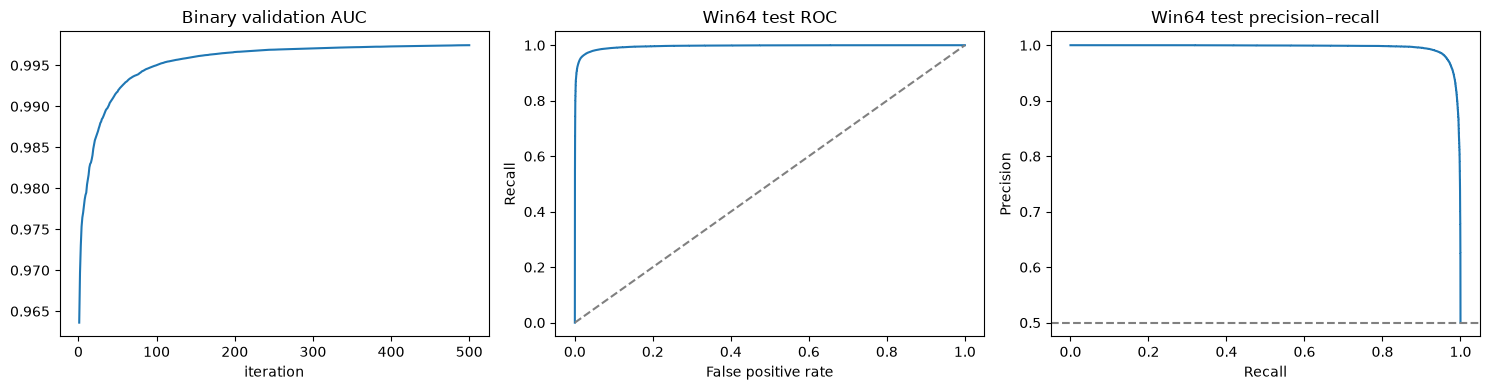

In [14]:
# Plot detector discrimination and validation history

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
history[["auc"]].plot(ax=axes[0], legend=False, title="Binary validation AUC")
test_y, test_p = y[idx["test"]], binary_scores["test"]
fpr, tpr, _ = roc_curve(test_y, test_p)
precision, recall, _ = precision_recall_curve(test_y, test_p)
axes[1].plot(fpr, tpr)
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set(title="Win64 test ROC", xlabel="False positive rate", ylabel="Recall")
axes[2].plot(recall, precision)
axes[2].axhline(test_y.mean(), ls="--", color="grey")
axes[2].set(title="Win64 test precision–recall", xlabel="Recall", ylabel="Precision")
fig.tight_layout()
fig.savefig(FIGURES / "binary_performance.png", dpi=150)
plt.show()


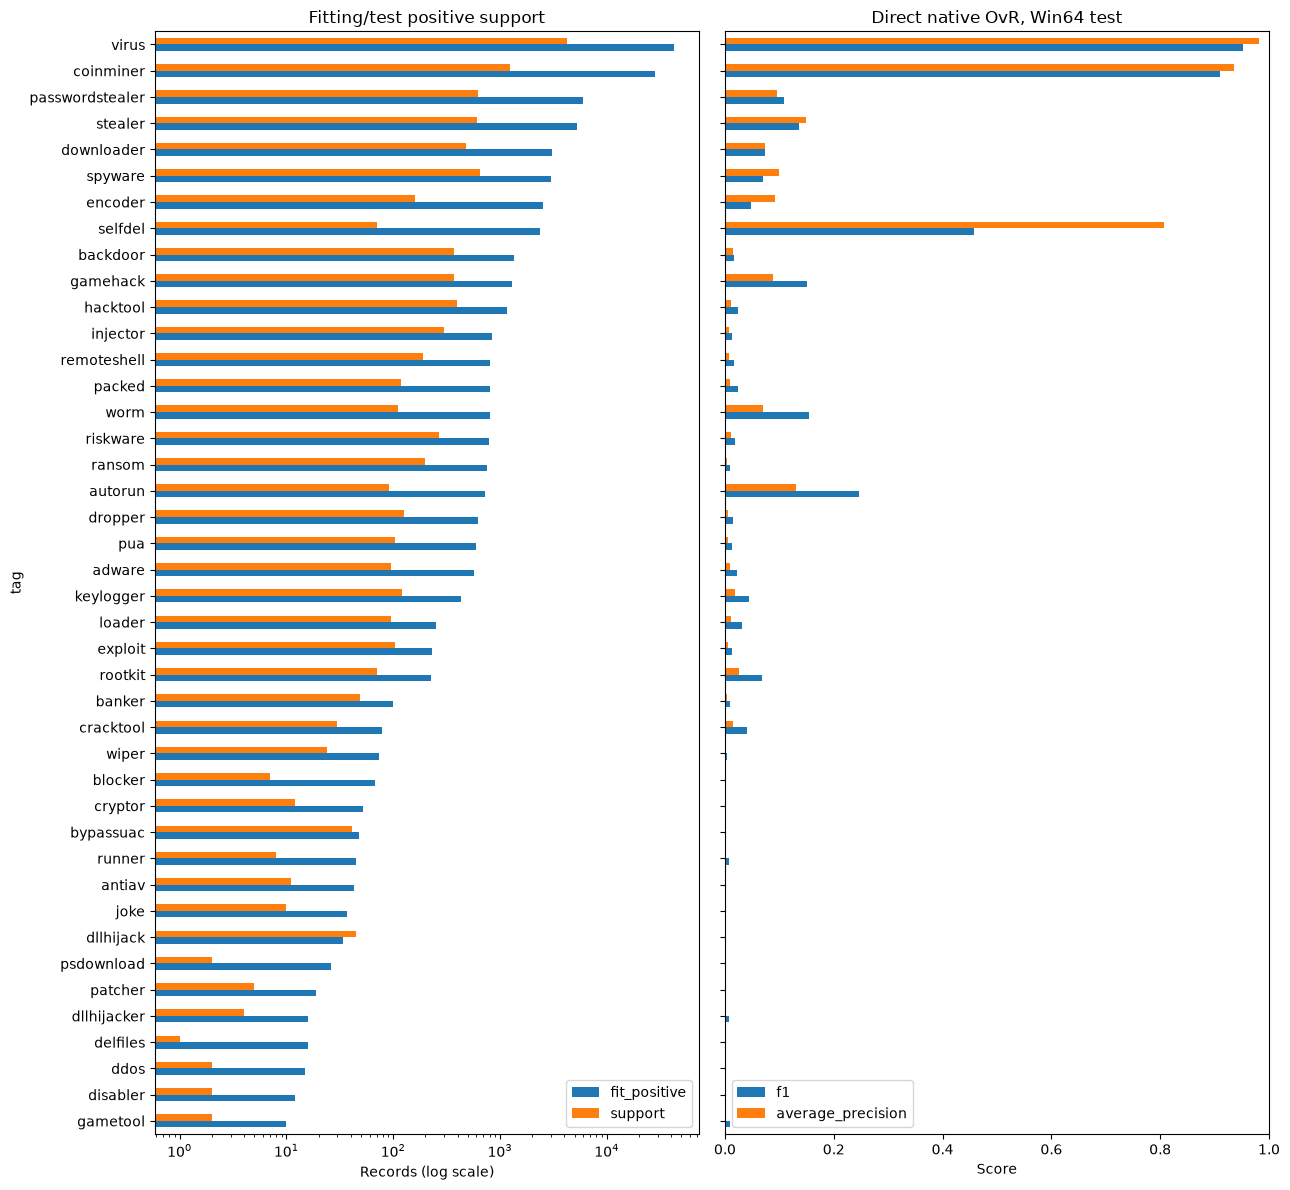

In [15]:
# Plot native tag support and performance

per_tag = pd.concat(per_tag_records)
view = per_tag.query(
    "split == 'test' and configuration == 'direct_ovr' "
    "and view == 'closed_world_all_rows'"
).set_index("tag")
view = view.join(support.set_index("tag")[["fit_positive"]]).sort_values("fit_positive")
fig, axes = plt.subplots(1, 2, figsize=(13, 12), sharey=True)
view[["fit_positive", "support"]].plot.barh(ax=axes[0], logx=True)
view[["f1", "average_precision"]].plot.barh(ax=axes[1])
axes[0].set(title="Fitting/test positive support", xlabel="Records (log scale)")
axes[1].set(title="Direct native OvR, Win64 test", xlabel="Score", xlim=(0, 1))
fig.tight_layout()
fig.savefig(FIGURES / "behavior_performance.png", dpi=150)
plt.show()


In [16]:
# Save row-aligned probabilities and exact configurations

saved = {"labels": np.asarray(labels)}
for split, scores in binary_scores.items():
    saved[split + "_rows"] = idx[split]
    saved[split + "_sha256"] = meta.iloc[idx[split]].sha256.to_numpy(dtype="U64")
    saved[split + "_binary_y"] = y[idx[split]]
    saved[split + "_behavior_y"] = Y[idx[split]]
    saved[split + "_binary_p"] = scores
    saved[split + "_behavior_p"] = behavior_scores[split]
np.savez_compressed(REPORT / "heldout_scores.npz", **saved)
configuration = {
    "binary": binary_config,
    "behavior": tag_config,
    "categorical_features": [2, 3, 4, 5, 6],
    "native_behavior_labels": labels,
    "class_min": 10,
    "normalization": None,
    "feature_selection": None,
    "PCA": None,
    "upstream": provenance,
    "environment": environment,
}
(REPORT / "configuration.json").write_text(json.dumps(configuration, indent=2))


3666

In [17]:
# Verify protected files and seal the completed run

assert protected_hashes(P) == protected_before
summary = {
    "completed": True,
    "features": 696,
    "fitting_rows": len(idx["fit"]),
    "source_records_sha256": source_sha,
    "vector_audit": vector_audit,
    "binary_rounds": binary_rounds,
    "binary_fit_seconds": binary_seconds,
    "behavior_heads": len(labels),
    "serialized_models": 0,
    "protocol": "chronological 40/6/6 training weeks; official test; separate challenge",
    "limits": [
        "local 696-feature Win64 adaptation; not the full upstream benchmark",
        "behavior absence is incompletely annotated; scores are weak-label agreement",
        "native tags differ from seven proposal roles; holdouts previously inspected",
        "challenge is all malware and includes non-Win64 formats",
    ],
    "protected_file_hashes": protected_before,
}
summary["output_file_hashes"] = {
    str(f.relative_to(REPORT)): hashlib.sha256(f.read_bytes()).hexdigest()
    for f in sorted(REPORT.rglob("*"))
    if f.is_file() and f.name != "run_summary.json"
}
(REPORT / "run_summary.json").write_text(json.dumps(summary, indent=2))
display(binary_table.query("split == 'test'"))
display(behavior_table.query("split == 'test' and configuration == 'direct_ovr'"))
print(
    "PASS: results sealed; prior analysis and scores unchanged; no models serialized."
)


,split,configuration,n,tn,fp,fn,tp,threshold,precision,recall,f1,fpr,roc_auc,average_precision,pr_auc_trapezoidal
4,test,repository_0.5,119892,58585,1347,2174,57786,0.500000,0.977221,0.963742,0.970435,0.022475,0.99563,0.995945,0.995945
5,test,calibration_fpr_1pct,119892,59420,512,4047,55913,0.825375,0.990926,0.932505,0.960828,0.008543,0.99563,0.995945,0.995945


,split,configuration,view,n,labels,threshold,micro_precision,micro_recall,micro_f1,macro_f1,macro_average_precision,macro_roc_auc,ap_supported_labels,auc_supported_labels,subset_accuracy,hamming_loss
12,test,direct_ovr,closed_world_all_rows,119892,42,0.5,0.031575,0.765071,0.060647,0.088506,0.087959,0.774346,42,42,0.217012,0.053792
13,test,direct_ovr,benign_and_annotated_malware,70195,42,0.5,0.075733,0.765071,0.137823,0.152696,0.132129,0.787655,42,42,0.335352,0.037107


PASS: results sealed; prior analysis and scores unchanged; no models serialized.


In [1]:
# Interpret the saved baseline results

from IPython.display import Markdown, display
from multi_label_static_analysis.config import project_paths
from multi_label_static_analysis.repository_baseline import baseline_readout

# This readout depends only on saved reports; it never retrains or tunes.
result_directory = project_paths().project / "results/repository_baseline"
display(Markdown(baseline_readout(result_directory)))
print("PASS: results interpreted with annotation and comparability limits.")


**Binary test.** At 0.5, F1 is 0.9704, recall 96.37% and FPR 2.25%. The calibration-selected threshold gives recall 93.25% and FPR 0.85%. Reducing false alarms costs detections; no test threshold was optimized.

**Native tags.** Direct OvR micro-F1 is 0.0606 (precision 3.16%, recall 76.51%). Detector gating changes micro-F1 to 0.0837 and recall to 75.32%. The gate removes tag predictions, including some correct ones.

**Annotation sensitivity.** Excluding unannotated malware changes direct micro-F1 to 0.1378; this is a different evaluation population. Missing tags and incorrect predictions both affect observed precision; these data cannot distinguish all cases.

**Instability and challenge.** 25/42 heads retained one round. Challenge recall is 67.37% at 0.5 across all formats. Its lack of benign examples prevents estimating challenge-only FPR or ROC AUC.

**Next experiments, not selected improvements.** Test per-tag calibration thresholds, compare class weighting and stopping metrics, then evaluate full PE features on the Win64 cohorts. [LightGBM documents](https://lightgbm.readthedocs.io/en/stable/Parameters.html#is_unbalance) that imbalance weighting can harm probability estimates; 0.5 need not be a useful operating point.

PASS: results interpreted with annotation and comparability limits.
